# DGSA

Complimenting: C:\Users\suzannevannoor\Nextcloud\Git_workspace2\20260727_empymod_pyGIMLi_DGSA_test_v1.ipynb

We implement the DGSA

In [26]:
import numpy as np

In [27]:
#Save information in order to compute DGSA

parameters = np.loadtxt("20260807_empymod_pyGIMLi_DGSA_test_v2_parameters.txt")
responses = np.loadtxt("20260807_empymod_pyGIMLi_DGSA_test_v2_responses.txt")

print(np.shape(parameters))
print(np.shape(responses))

(1050, 4)
(1050, 5)


In [28]:
# Now, calculate the euclidean distances between model responses
from scipy.spatial.distance import pdist, squareform

distances = pdist(responses, metric="euclidean")
distances = squareform(distances)

In [35]:
# Cluster the responses using KMedoids
from pyDGSA.cluster import KMedoids

n_clusters = 15
clusterer = KMedoids(n_clusters=n_clusters, max_iter=3000, tol=1e-4)
labels, medoids = clusterer.fit_predict(distances)

In [36]:
# Calculate mean sensitivity across clusters
from pyDGSA.dgsa import dgsa

sens = dgsa(parameters, labels, parameter_names=["anomaly resistivity", "anomaly thickness", "anomaly depth", "relative noise level"], confidence=True)
print(sens)

  0%|          | 0/3000 [00:00<?, ?it/s]

                      sensitivity  confidence
anomaly resistivity      4.132073    2.519433
anomaly thickness        0.538270    0.329161
anomaly depth            0.373057    0.233572
relative noise level     1.928083    1.217238


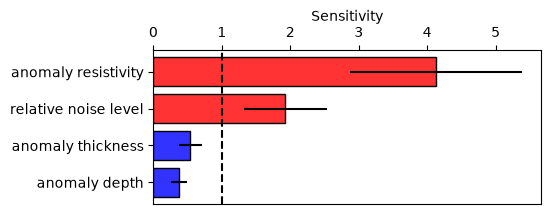

In [37]:
# Generate a pareto plot of the results
from pyDGSA.plot import vert_pareto_plot

fig, ax = vert_pareto_plot(sens, confidence=True)